Image shape: (6000, 4000, 3)
HSV shape: (6000, 4000, 3) | LAB shape: (6000, 4000, 3)


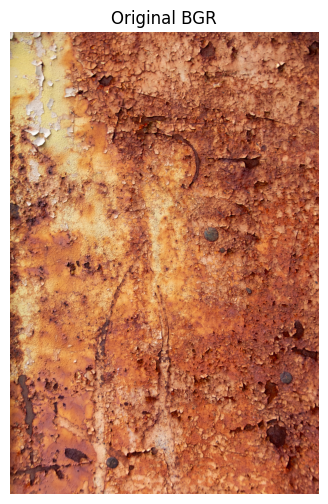

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("../data/defect.jpg")
if img is None:
    raise FileNotFoundError("data/defect.jpg not found")

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
print("Image shape:", img.shape)
print("HSV shape:", hsv.shape, "| LAB shape:", lab.shape)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original BGR")
plt.axis("off")
plt.show()

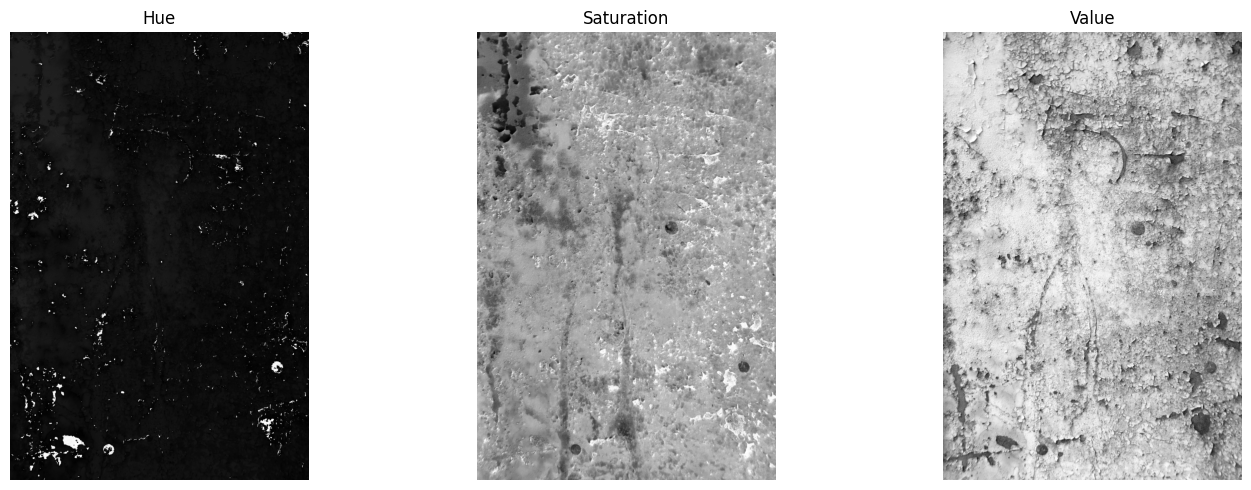

In [6]:
h, s, v = cv2.split(hsv)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(h, cmap="gray"); axes[0].set_title("Hue")
axes[1].imshow(s, cmap="gray"); axes[1].set_title("Saturation")
axes[2].imshow(v, cmap="gray"); axes[2].set_title("Value")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

Mask pixels set: 20804862


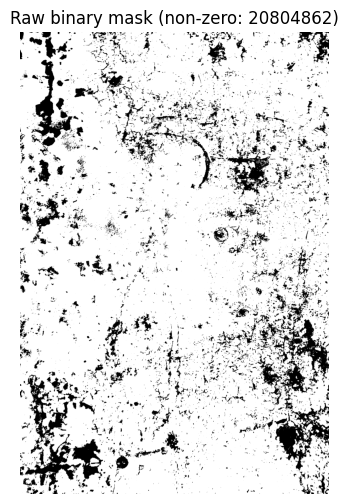

In [7]:
# Tune these to your image. Orange/rust tones:
lower = np.array([5, 80, 80])
upper = np.array([30, 255, 255])
mask = cv2.inRange(hsv, lower, upper)
print("Mask pixels set:", np.count_nonzero(mask))

plt.figure(figsize=(10, 6))
plt.imshow(mask, cmap="gray")
plt.title(f"Raw binary mask (non-zero: {np.count_nonzero(mask)})")
plt.axis("off")
plt.show()

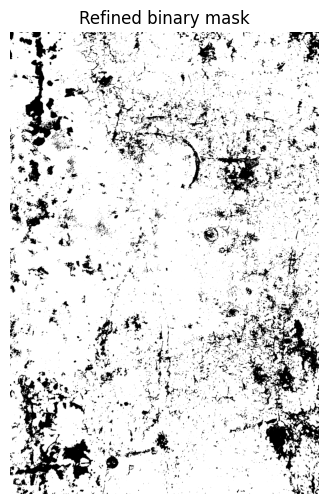

In [8]:
_, mask_refined = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10, 6))
plt.imshow(mask_refined, cmap="gray")
plt.title("Refined binary mask")
plt.axis("off")
plt.show()

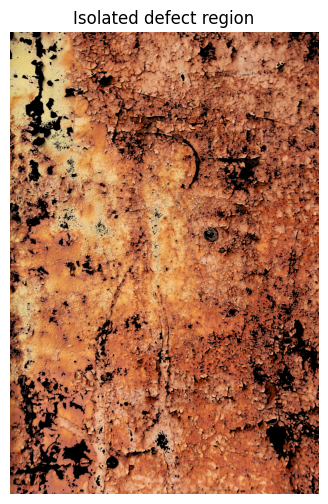

In [9]:
isolated = cv2.bitwise_and(img, img, mask=mask_refined)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(isolated, cv2.COLOR_BGR2RGB))
plt.title("Isolated defect region")
plt.axis("off")
plt.show()

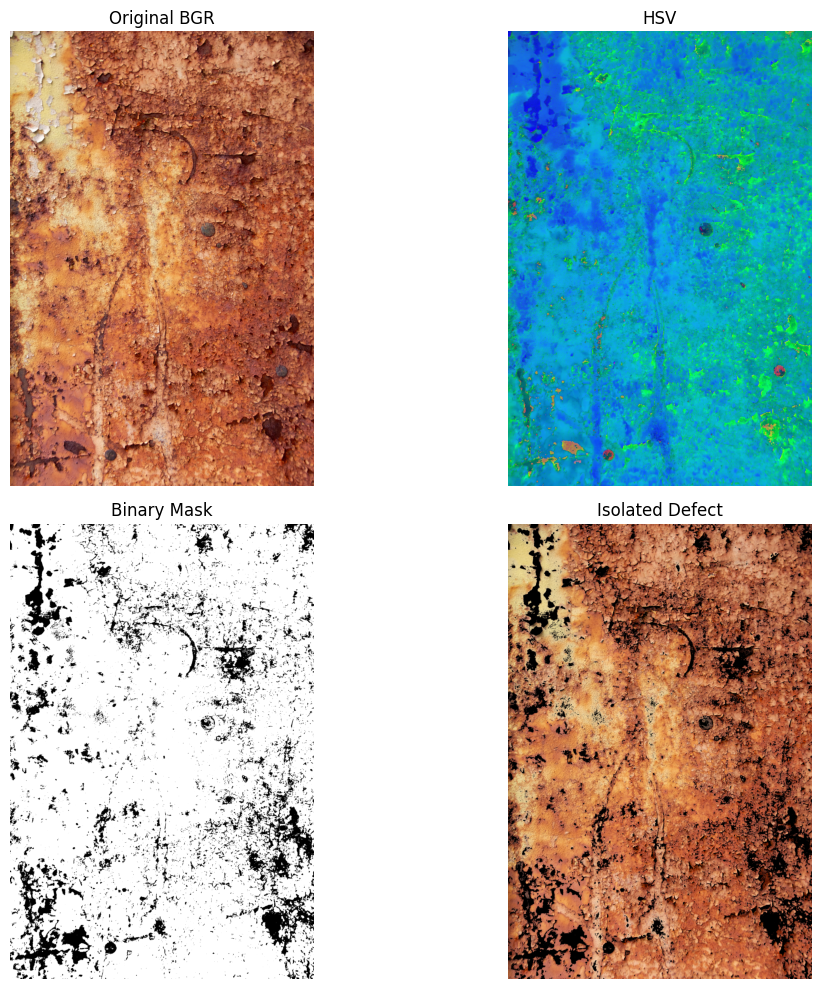

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Original BGR")
axes[0, 1].imshow(hsv);                                   axes[0, 1].set_title("HSV")
axes[1, 0].imshow(mask_refined, cmap="gray");             axes[1, 0].set_title("Binary Mask")
axes[1, 1].imshow(cv2.cvtColor(isolated, cv2.COLOR_BGR2RGB)); axes[1, 1].set_title("Isolated Defect")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig("../outputs/task2_threshold.png", dpi=150)
plt.show()